<a href="https://colab.research.google.com/github/jacobryan02/Dashboards/blob/master/CNSAssigment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Preamble get all in ONCE!
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from sklearn.decomposition import PCA



Since $\sigma_z = 0 $ then $n = \mu_{\mathbf{n}} = 0$ and $\mathbf{z} = \mathbf{\mu}(\theta) $ for each neuron i, $\mathbf{z}$ is deterministic in this case. Then we project $\mathbf{z}$ onto matrix $W_{in}$ and apply the ReLU transformation to compute $\mathbf{λ}$.

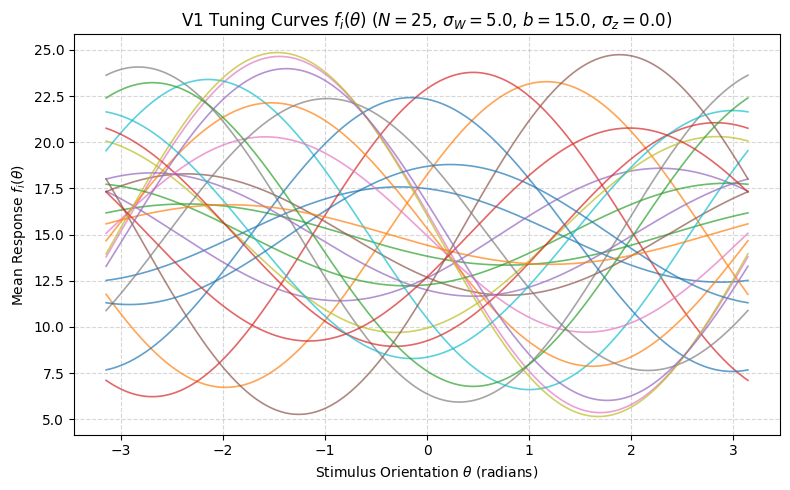

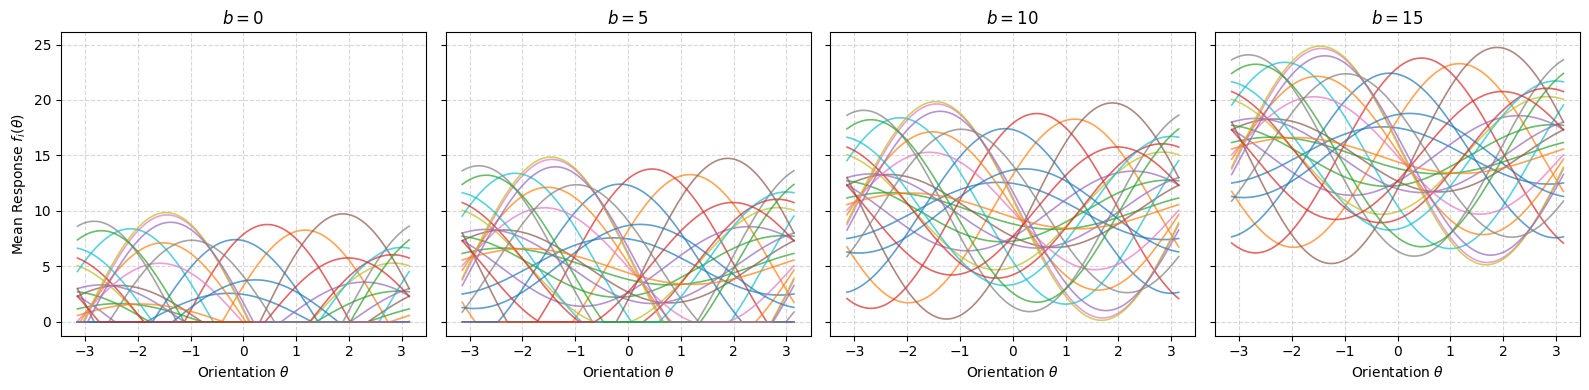

In [2]:
#Question 1.1

# Parameters
np.random.seed(42)  # for reproducibility
N = 25
sigma_W = 5.0
sigma_z = 0.0       # Zero trial noise variance so deterministic Z
theta_grid = np.linspace(-np.pi, np.pi, 360)

# Weight Initialisation , Win,ij ~ N(0, sigma_W^2)
Win = np.random.normal(loc=0.0, scale=sigma_W, size=(N, 2))

def get_tuning_curves(theta_arr, Win_matrix, b):
    """
    Compute deterministic tuning curves f_i(theta) given sigma_z = 0.
    mu(theta) = [cos(theta), sin(theta)]^T, lambda = max(Win * mu(theta) + b, 0)
    """
    # mu(theta)
    mu = np.vstack([np.cos(theta_arr), np.sin(theta_arr)])
    # Project W_in @ mu(theta) = W_in @ z
    lin_prod = np.dot(Win_matrix, mu)
    # Elementwise ReLU
    f_theta = np.maximum(0, lin_prod + b)
    return f_theta

# Question 1.1: b = 15
b_val_1 = 15.0
f_b15 = get_tuning_curves(theta_grid, Win, b=b_val_1)
plt.figure(figsize=(8, 5))

for i in range(N):
    plt.plot(theta_grid, f_b15[i, :], alpha=0.7, linewidth=1.2)
plt.title(rf"V1 Tuning Curves $f_i(\theta)$ ($N={N}$, $\sigma_W={sigma_W}$, $b={b_val_1}$, $\sigma_z={sigma_z}$)")
plt.xlabel(rf"Stimulus Orientation $\theta$ (radians)")
plt.ylabel(rf"Mean Response $f_i(\theta)$")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("q1_1_tuning_curves_b15.png", dpi=300)
plt.show()

# 1.2: changes of curves, scaling b from 15 to 0
b_values = [0, 5, 10, 15]

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)

for idx, b_val in enumerate(b_values):
    # Compute tuning curves for every b
    f_b = np.maximum(0, np.dot(Win, np.vstack([np.cos(theta_grid), np.sin(theta_grid)])) + b_val)

    # Plot all on one
    for i in range(N):
        axes[idx].plot(theta_grid, f_b[i, :], alpha=0.7, linewidth=1.2)

    axes[idx].set_title(f"$b = {b_val}$")
    axes[idx].set_xlabel(r"Orientation $\theta$")
    if idx == 0:
        axes[idx].set_ylabel(r"Mean Response $f_i(\theta)$")
    axes[idx].grid(True, linestyle="--", alpha=0.5)

####maybe 2x2 grid for writeup
plt.tight_layout()
plt.savefig("tuning_curves_b_sweep.png", dpi=300)
plt.show()

# 1.1
For each $\theta,\text{ } \mathbf{\mu} (\theta)$ is a linear combination of $\cos \theta $ and $\sin \theta$, which yields phase shifted cosine waves. The ReLU function half-wave rectifies each wave to create localised tuning windows where neurons respond selectively to precise orientations.

# 1.2
As bias $b$ increases from $0$ to $15$, the upward shift of $b$ reduces the truncating effect of the rectifying non-linearity (ReLU). At $b=0$, negative rates are heavily muted to zero in which neurons remain silent for non selected orientations. In contrast, increasing $b$ to 15 ascends the baseline firing rate across the population. This essentially replaces ReLU with the identity function and results in continuous tuning curves across all orientations.





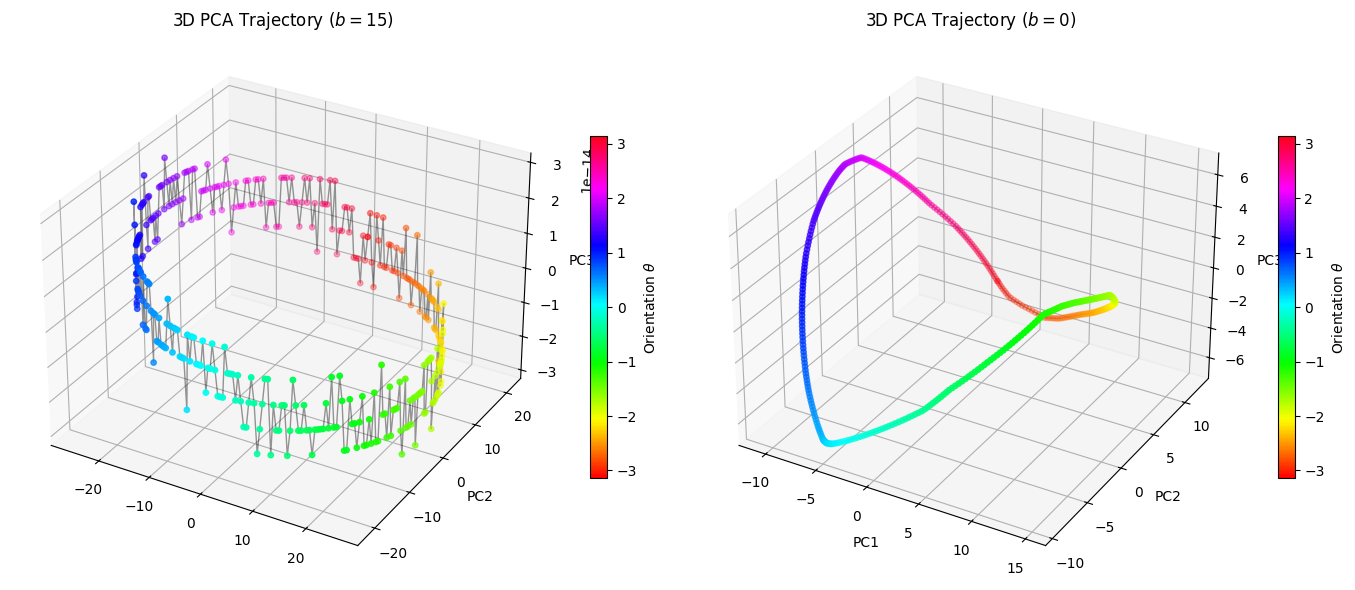

In [6]:
# 1.3 PCA
# Global Parameters
np.random.seed(42)
N = 25
sigma_W = 5.0
theta_grid = np.linspace(-np.pi, np.pi, 360) # N_stim = 360
N_stim = len(theta_grid)

Win = np.random.normal(loc=0.0, scale=sigma_W, size=(N, 2))

# Stimulus feature matrix mu(theta)
mu = np.vstack([np.cos(theta_grid), np.sin(theta_grid)])

def get_tuning_matrix(Win, mu, b):
    """
    Compute tuning matrix F of shape (N_stim, N) and each column is each neuron's tuning curve and each row is corresponding to the stimulus orientations.
    """
    # Linear projection: W_in @ mu(theta)
    linear_proj= np.dot(Win, mu)
    # Apply ReLU with b (N, N_stim)
    f_matrix = np.maximum(0, linear_proj + b)
    # Transpose to get F = [f_1(theta), ..., f_N(theta)]
    return f_matrix.T

# Compute PCA (b = 15, b = 0)
def compute_pca_trajectory(F_matrix):
    pca = PCA(n_components=3)
    pcs = pca.fit_transform(F_matrix)
    return pcs, pca.explained_variance_ratio_

# b = 15
F_b15 = get_tuning_matrix(Win, mu, b=15)
pcs_b15, var_b15 = compute_pca_trajectory(F_b15)

# b = 0
F_b0 = get_tuning_matrix(Win, mu, b=0)
pcs_b0, var_b0 = compute_pca_trajectory(F_b0)

# 3D Plotting
fig = plt.figure(figsize=(14, 6))
# Plot for b = 15
ax1 = fig.add_subplot(121, projection='3d')
sc1 = ax1.scatter(pcs_b15[:, 0], pcs_b15[:, 1], pcs_b15[:, 2],
                  c=theta_grid, cmap='hsv', s=15)
ax1.plot(pcs_b15[:, 0], pcs_b15[:, 1], pcs_b15[:, 2], color='black', alpha=0.4, linewidth=1)
ax1.set_title(f"3D PCA Trajectory ($b = 15$)")
ax1.set_ylabel("PC2")
ax1.set_zlabel("PC3")
fig.colorbar(sc1, ax=ax1, label=r"Orientation $\theta$", shrink=0.6)

# Plot for b = 0
ax2 = fig.add_subplot(122, projection='3d')
sc2 = ax2.scatter(pcs_b0[:, 0], pcs_b0[:, 1], pcs_b0[:, 2],
                  c=theta_grid, cmap='hsv', s=15)
ax2.plot(pcs_b0[:, 0], pcs_b0[:, 1], pcs_b0[:, 2], color='black', alpha=0.4, linewidth=1)
ax2.set_title(f"3D PCA Trajectory ($b = 0$)")
ax2.set_xlabel("PC1")
ax2.set_ylabel("PC2")
ax2.set_zlabel("PC3")
fig.colorbar(sc2, ax=ax2, label=r"Orientation $\theta$", shrink=0.6)

plt.tight_layout()
plt.savefig("pca_3d_trajectories.png", dpi=300)
plt.show()

# 1.4
At the single-neuron level, stimulus orientation $\theta$ is encoded via smooth, bell-shaped tuning curves for $b = 0$ where individual neuron curves show a selection to preferred orientations determined by random projection weights $W_{in}$. Moving across the population $N=25$, this forms a smooth, continuous closed ring manifold in neural state space as $\theta$ spans through $[-\pi, \pi)$.

The population is heavily modulated by bias $b$. At high $b$ ($b = 15$), tuning curves are shifted uniformly upward, yielding dense population activity where neurons remain continuously active across all orientations. Conversely, at $b = 0$, the ReLU Non linearity heavily truncates low or negative activations to zero. This enforces selective sparse coding, causing neurons to be silent across wide intervals of orientations and introducing sharp non-linearities into the state-space trajectory.
A high positive bias translates neuron firing rates operating above the zero cutoff, allowing smooth rate modulation. Whereas, setting $b = 0$, the baseline is at zero, incongruently truncating below threshold rates. There is a fundamental compromise between metabolic efficiency via sparse firing (low/zero bias) and lossless information transmission (high bias).

# Question 2


#2.1

For the PV decoder we often assume that tuning curves are homogeneous, symmetric and uniformly distributed since we are essentially fitting a smooth translated cosine function to the response.
However in the present model there are several strucural difficulties that arise to make PV decoding redundant.
Since each input weight $W_{in, ij}$ is independently distributed from a zero-mean
Gaussian ($\mathcal{N}(0, \sigma_W^2)$), individual neurons have majorly different peak firing rates ($\max_\theta f_i(\theta)$).
Without modification, neurons with large random weights will dominate the vector sum, biasing the decoded estimate towards their preferred orientations ($\theta_i$) regardless of the true stimulus. The interaction of random projections of weights  and ReLU create many heterogenous, overlapping and asymmetric tuning profiles rather than identical, evenly spaced, symmetric Gaussians we expect.

Low bias $b$ values cause substantial portions of tuning curves to clip at zero across large angular intervals, breaking spatial symmetry across the population representation.

Normalizing each neuron's response by its maximum expected firing rate mitigates some of the issues outlined.
The rescaling of each neuron's activity to a relative scale drops the effect of random gain biases from high magnitudes of $W_{in}$.
Thus every neuron contributes to PV based on its relative activation level for the stimulus instead of basline activity or the weighted scale.
This prevents directional bias of PV improves relative accuracy of decoded $\hat{\theta}$ to true stimulus θ.

# 2.2
Template matching considers the entire template, and analogous to taking the mean instead of the mode, the bias of higher weighted terms is supressed. The Template Matching Decoder finds the theta that generates the smallest sum of the pointwise (single neuron) differences to the actual spike count. Since the entirety of each template's 'closeness' to the the true population's count vector $\mathbf{x}$ is considered, sparse but extreme high-weighted terms have less bearing on selecting $\hat{\theta}$.
Template matching has greater sensitivity to the general profile of the tuning curves than to localised bumpy behaviour.

We assume there is zero input noise ($\sigma_z = 0$) to ensure that firing rates are deterministic functions of the stimulus $ \theta $ and to prevent overdispersion. Otherise, the overdispersion is a violation to the assumption of poisson's variance mean equality.
We assume the sytem is purely feedforward and uncoupled to other tuning curves. This guarantees spike counts are conditionally independent across neurons given the stimulus. That is $p( \mathbf{x} \mid \theta) = \prod_i p(x_i \mid \theta)$ which is required to deduce the likelihood expression provided.
Put explicity, it is used in the second equality of the below derivation of log likelihood:
\begin{aligned}
\ell(\theta) &= \log p(\mathbf{x} \mid \theta) \\
&= \log \left( \prod_i \frac{f_i(\theta)^{x_i} e^{-f_i(\theta)}}{x_i!} \right) \\
&= \sum_i \log \left( \frac{f_i(\theta)^{x_i} e^{-f_i(\theta)}}{x_i!} \right) \\
&= \sum_i \left( x_i \log f_i(\theta) - f_i(\theta) - \log x_i! \right)
\end{aligned}




# 2.3

In [11]:
#Preamble
import numpy as np
import matplotlib.pyplot as plt

def circ_dist(a, b):
    d = np.abs(a - b)
    return np.minimum(d, 2*np.pi - d)

def mu_of(theta):
    """Input-layer mean, shape (2, len(theta))."""
    return np.vstack([np.cos(theta), np.sin(theta)])

def relu(u):
    return np.maximum(u, 0)

In [8]:
def make_network(N, sigma_W, b, theta_grid, rng):
    W = rng.normal(0, sigma_W, size=(N, 2))
    f_grid = relu(W @ mu_of(theta_grid) + b)  # noiseless tuning curves
    theta_pref = theta_grid[np.argmax(f_grid, axis=1)]
    f_max = np.maximum(f_grid.max(axis=1), 1e-8)  # for normalised PV
    return W, f_grid, theta_pref, f_max


from scipy.stats import norm

#for 2.4 and 3.4 and 4
def expected_relu(m, s):
    """E[max(u,0)] for u ~ N(m, s^2). m: (N,G), s: (N,1).
    Closed form m*Phi(m/s) + s*phi(m/s); falls back to relu(m) where s = 0."""
    s_safe = np.where(s > 0, s, 1.0)
    f = m * norm.cdf(m / s_safe) + s_safe * norm.pdf(m / s_safe)
    return np.where(s > 0, f, relu(m))

def make_network(N, sigma_W, b, theta_grid, rng, sigma_z=0.0, noiseless=False):
    """
    noiseless=True  -> Tuning curves relu(W mu + b), for sigma_z = 0.
    noiseless=False -> Expected tuning curves E_n[relu(W(mu+n) + b)].
                       Needed for sigma_z > 0 cases.

    """
    W = rng.normal(0, sigma_W, size=(N, 2))
    m = W @ mu_of(theta_grid) + b

    if noiseless:
        f_grid = relu(m)                          # Q2.3 only
    else:
        s = sigma_z * np.linalg.norm(W, axis=1, keepdims=True)
        f_grid = expected_relu(m, s)              # Q2.4/3.4/4

    theta_pref = theta_grid[np.argmax(f_grid, axis=1)]
    f_max = np.maximum(f_grid.max(axis=1), 1e-8)
    return W, f_grid, theta_pref, f_max


In [12]:
# Vectorised Tuning Curves
def decode_PV(x, theta_pref, f_max):
    xt = x / f_max  # normalise
    return np.arctan2(xt @ np.sin(theta_pref), xt @ np.cos(theta_pref)) % (2*np.pi)

def decode_TM(x, f_grid, theta_grid):
    # sum_i (F_ig - x_i)^2 = |F_g|^2 - 2 x.F_g + |x|^2 ; the |x|^2 term is constant in g, grid point
    cost = (f_grid**2).sum(0)[None, :] - 2 * x @ f_grid
    return theta_grid[np.argmin(cost, axis=1)]


def decode_ML(x, f_grid, theta_grid):
    # l = sum_i x_i log f_i - f_i
    #(log x! is dropped; independent of theta)
    logf = np.log(np.maximum(f_grid, 1e-300)) #f floored to prevent explosion
    ll = x @ logf - f_grid.sum(0)[None, :]
    return theta_grid[np.argmax(ll, axis=1)]

In [36]:
def evaluate_decoders(N=25, sigma_W=5.0, sigma_z=0.0, b=5.0,
                      n_networks=80, n_stim=18, n_trials=10,
                      n_grid=360, seed=0, noiseless=False):
    theta_grid = np.linspace(0, 2*np.pi, n_grid, endpoint=False)
    test_theta = np.linspace(0, 2*np.pi, n_stim, endpoint=False)
    mu_test = mu_of(test_theta)
    mse = {"PV": [], "TM": [], "ML": []}

    for k in range(n_networks):
        rng = np.random.default_rng(seed * 100_000 + k)
        W, f_grid, theta_pref, f_max = make_network(
            N, sigma_W, b, theta_grid, rng, sigma_z=sigma_z, noiseless=noiseless)

        z = mu_test.T[None] + rng.normal(0, sigma_z, size=(n_trials, n_stim, 2))
        x = rng.poisson(relu(z @ W.T + b)).reshape(-1, N)
        true = np.tile(test_theta, n_trials)

        est = {"PV": decode_PV(x, theta_pref, f_max),
               "TM": decode_TM(x, f_grid, theta_grid),
               "ML": decode_ML(x, f_grid, theta_grid)}
        for d in mse:
            mse[d].append(np.mean(circ_dist(est[d], true)**2))

    return {d: np.array(v) for d, v in mse.items()}

In [37]:
baseline = dict(N=25, sigma_W=5.0, sigma_z=0.0, b=5.0,
            n_networks=20, n_stim=36, n_trials=20)

def convergence_test(parameter, values, repeats=5):
    out = {}

    for v in values:
        # one list of scores per decoder, one entry per repeat
        pv_scores = []
        tm_scores = []
        ml_scores = []

        for s in range(repeats):
            settings = baseline.copy()
            settings[parameter] = v
            res = evaluate_decoders(**settings, seed=s)

            # res["PV"] is an array of per-network MSEs so we take average
            pv_scores.append(np.mean(res["PV"]))
            tm_scores.append(np.mean(res["TM"]))
            ml_scores.append(np.mean(res["ML"]))

        # mean and spread across the repeats for each decoder
        pv_mean, pv_std = np.mean(pv_scores), np.std(pv_scores)
        tm_mean, tm_std = np.mean(tm_scores), np.std(tm_scores)
        ml_mean, ml_std = np.mean(ml_scores), np.std(ml_scores)

        # store the results
        out[v] = {
            "PV": (pv_mean, pv_std),
            "TM": (tm_mean, tm_std),
            "ML": (ml_mean, ml_std),
        }

        # print one line per v
        print(f"{parameter}={v}")
        print(f"   PV: {pv_mean:.4f} +/- {pv_std:.4f}")
        print(f"   TM: {tm_mean:.4f} +/- {tm_std:.4f}")
        print(f"   ML: {ml_mean:.4f} +/- {ml_std:.4f}")

    return out

network_results  = convergence_test("n_networks", [5, 10, 20, 40, 80])
stimulus_results = convergence_test("n_stim",     [9, 18, 36, 72, 144])
trial_results    = convergence_test("n_trials",   [5, 10, 20, 40, 80])

n_networks=5
   PV: 0.1220 +/- 0.0432
   TM: 0.0143 +/- 0.0014
   ML: 0.0077 +/- 0.0007
n_networks=10
   PV: 0.1391 +/- 0.0402
   TM: 0.0141 +/- 0.0007
   ML: 0.0075 +/- 0.0005
n_networks=20
   PV: 0.1446 +/- 0.0197
   TM: 0.0142 +/- 0.0006
   ML: 0.0074 +/- 0.0004
n_networks=40
   PV: 0.1612 +/- 0.0089
   TM: 0.0140 +/- 0.0003
   ML: 0.0074 +/- 0.0002
n_networks=80
   PV: 0.1733 +/- 0.0182
   TM: 0.0143 +/- 0.0003
   ML: 0.0076 +/- 0.0002
n_stim=9
   PV: 0.1459 +/- 0.0211
   TM: 0.0140 +/- 0.0005
   ML: 0.0074 +/- 0.0004
n_stim=18
   PV: 0.1443 +/- 0.0204
   TM: 0.0140 +/- 0.0004
   ML: 0.0076 +/- 0.0003
n_stim=36
   PV: 0.1446 +/- 0.0197
   TM: 0.0142 +/- 0.0006
   ML: 0.0074 +/- 0.0004
n_stim=72
   PV: 0.1442 +/- 0.0199
   TM: 0.0141 +/- 0.0005
   ML: 0.0075 +/- 0.0004
n_stim=144
   PV: 0.1448 +/- 0.0206
   TM: 0.0142 +/- 0.0006
   ML: 0.0075 +/- 0.0004
n_trials=5
   PV: 0.1444 +/- 0.0202
   TM: 0.0141 +/- 0.0006
   ML: 0.0076 +/- 0.0005
n_trials=10
   PV: 0.1437 +/- 0.0211
   TM: 0

For the ML and TM decoders, it is clear that n_stim has converged between 9 and 18, similarly n_trials has seemingly converged between 5 and 10 for the  since no further significant changes are seen between 10 and 80 (relative to burn in period) .
PV is heavy tailed across all networks so n_trials = 80 is chosen provided the compute power isn't to large.

We choose the smallest value where the mean has stopped drifting and the spread across repeats are small compared with the differences of interest (for example, TM vs ML).

In [33]:
# default parameter setup inferred  by previous chunk
def sweep(parameter, values, n_networks=80, n_stim=18, n_trials=10, seed=0):
    res = {d: [] for d in ["PV", "TM", "ML"]}
    for v in values:
        out = evaluate_decoders(**{**baseline, parameter: v, "n_networks": n_networks,
                                   "n_stim": n_stim, "n_trials": n_trials}, seed=seed)
        for d in res:
            res[d].append((out[d].mean(), out[d].std(ddof=1)/np.sqrt(n_networks)))
    return {d: np.array(v) for d, v in res.items()}

N_values     = [10, 15, 25, 40, 70, 100]
sigma_values = [1, 2, 3, 5, 8]
b_values     = [0, 1, 2.5, 5, 7.5, 10, 12.5, 15]

res_N = sweep("N", N_values)
res_s = sweep("sigma_W", sigma_values)
res_b = sweep("b", b_values)

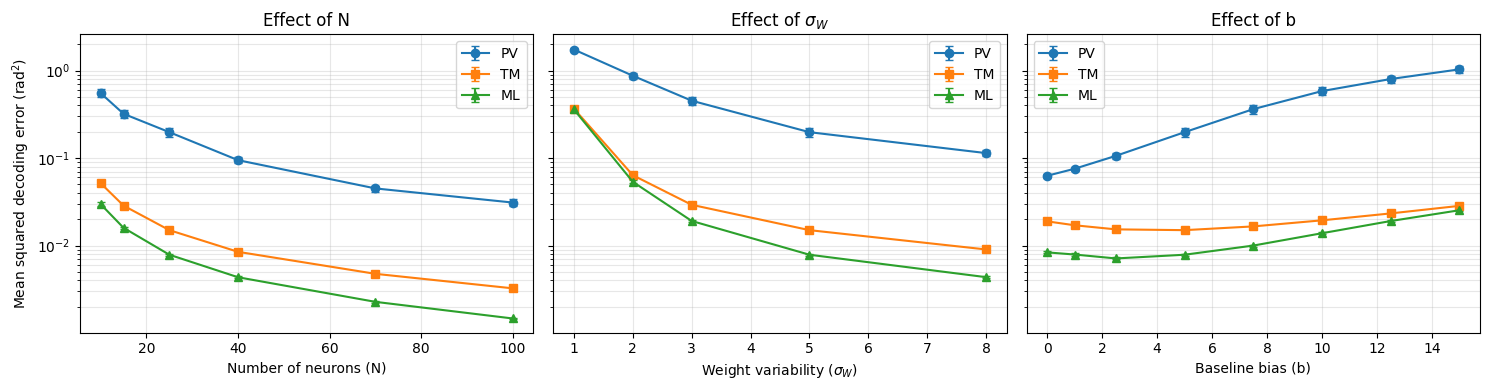

In [34]:
def plot_sweep(ax, xs, res, xlabel, title):
    for d, m in zip(["PV", "TM", "ML"], ["o", "s", "^"]):
        ax.errorbar(xs, res[d][:, 0], yerr=res[d][:, 1], fmt=m+"-", capsize=3, label=d)
    ax.set_yscale("log"); ax.set_xlabel(xlabel); ax.set_title(title)
    ax.grid(True, which="both", alpha=0.3); ax.legend()

fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
plot_sweep(ax[0], N_values, res_N, "Number of neurons (N)","Effect of N")
plot_sweep(ax[1], sigma_values, res_s, r"Weight variability ($\sigma_W$)", "Effect of $\\sigma_W$")
plot_sweep(ax[2], b_values,     res_b, "Baseline bias (b)","Effect of b")
ax[0].set_ylabel("Mean squared decoding error (r$^2$)")
plt.tight_layout(); plt.show()


With $\sigma_z = 0 $, the only trial-to-trial variability arises from independent Poisson spiking and the difference in performance between the three decoders is given by how well the tuning curve is used by each. ML is the most accurate because it uses the correct Poisson noise model, in which variance grows with the mean. TM is about 1.5 to 2 times worse for decoding since it considers all neurons to have equal noise. PV is over 10 times worse than both with heavy tails because it doesn't capture tuning-curve shapes and is biased by the baseline. This ordering of performance holds across every parameter that we sweep through.

The increase of population size from 10 to 100 reduces decoding error as 1/N for all three decoders. This alligns with theoretical expectation as Fisher information is additive and grows linearly with N. Thus the estimated variance, proportional to the mean squared error must decrease along a translated 1/N. PV follows this behaviour but does not

Increasing $\sigma_W $ improves accuracy with diminishing returns while stimulus driven variance stays consistenly small relative to the  asymptotic baseline, where $\sigma_W$ is less than around 3. After this the MSE scales with approximately $1/ \sigma_W$

Contrastingly the bias $b$ affects the decoders asymmetrically. For PV, increasing $b$from 0 to 15 introduces a stimulus-independent offset that causes error to rise steeply and monotonically. For TM and ML, $b$'s effect is more subtle showing  a shallow optimum at around $b \approx 2.5$ where error is minimised, before rising at larger $b$ values due to excess Poisson variance. Considered together, decoding error is minimised by pairing the ML decoder with a large population, high weight variability ($\sigma_W$), and a low-to-moderate baseline $b$.

ML achieves optimal accuracy by maximizing $N = 100$ and $\sigma_W = 8$ alongside a low-to-moderate baseline bias around $b \approx 2.5$.
TM requires the same high $N$ and $\sigma_W$ with an intermediately sized $b \approx 2.5$ - $5$.In fact TM converges in performance with ML at extreme $b = 15$ or very low weight variability $\sigma_W = 1$. Finally, PV also benefits from maximising $N$ and $\sigma_W$ but strictly requires minimising baseline bias to $b = 0$ to avoid monotonic error growth, though it remains an order of magnitude less accurate overall.

# 2.4
For this question we define n_networks = 40 rather than 80 due to computational restraints and because for $\sigma_z = 0$ PV is not converged at 40 nor 80. But we do know that ML and TM are converged by n_networks = 20. At $\sigma_z = 0.2$, doubling to 80 changed the MSE by at most 2% for all decoders.


In [18]:
for n in [50, 400]:
    for nn in [40, 80]:
        out = evaluate_decoders(N=n, sigma_z=0.2, n_networks=nn, n_stim=18, n_trials=10, seed=0)
        print(f"N={n} nets={nn} | " + " | ".join(f"{d}: {out[d].mean():.4f}" for d in out))

N=50 nets=40 | PV: 0.1277 | TM: 0.0500 | ML: 0.0464
N=50 nets=80 | PV: 0.1262 | TM: 0.0510 | ML: 0.0473
N=400 nets=40 | PV: 0.0495 | TM: 0.0428 | ML: 0.0427
N=400 nets=80 | PV: 0.0501 | TM: 0.0428 | ML: 0.0425


In [16]:
N_big     = [10, 25, 50, 100, 200, 400, 800]
sz_values = [0, 0.05, 0.1, 0.2, 0.4]

res_sz = {}   # res_sz[sz][decoder] = list of (mean, sem), one entry per N

for sz in sz_values:
    res_sz[sz] = {"PV": [], "TM": [], "ML": []}
    for n in N_big:
        out = evaluate_decoders(N=n, sigma_W=5.0, b=5.0, sigma_z=sz,
                                n_networks=40, n_stim=18, n_trials=10, seed=0)
        for d in ["PV", "TM", "ML"]:
            vals = out[d]
            res_sz[sz][d].append((vals.mean(), vals.std(ddof=1)/np.sqrt(len(vals))))
    print("finished sigma_z =", sz)

finished sigma_z = 0
finished sigma_z = 0.05
finished sigma_z = 0.1
finished sigma_z = 0.2
finished sigma_z = 0.4


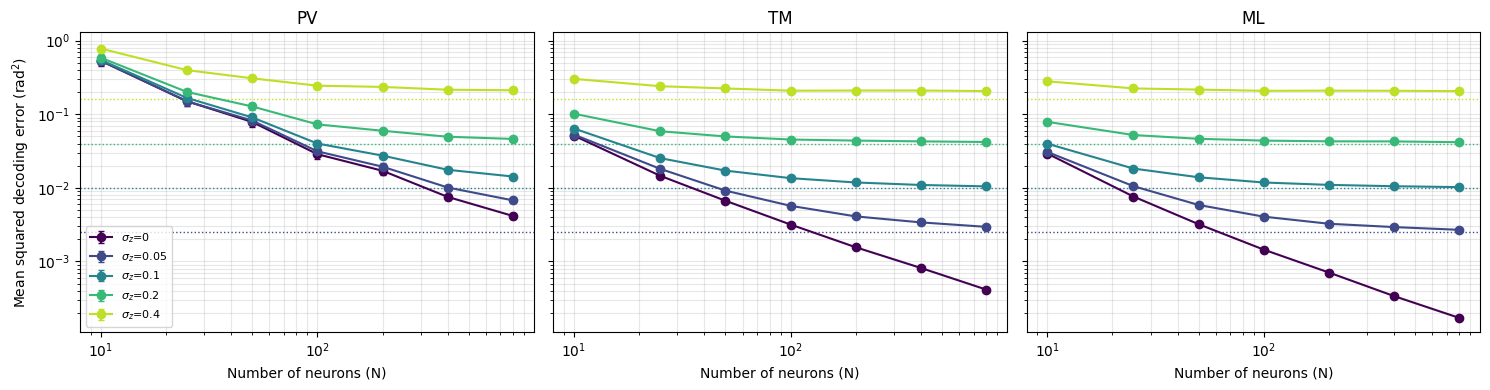

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
colors = plt.cm.viridis(np.linspace(0, 0.9, len(sz_values)))

for ax, d in zip(axes, ["PV", "TM", "ML"]):
    for c, sz in zip(colors, sz_values):
        arr = np.array(res_sz[sz][d])
        ax.errorbar(N_big, arr[:, 0], yerr=arr[:, 1], color=c, marker="o",
                    capsize=2, label=fr"$\sigma_z$={sz}")
        if sz > 0:
            ax.axhline(sz**2, color=c, ls=":", lw=1)      # small-noise floor sigma_z^2
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Number of neurons (N)"); ax.set_title(d)
    ax.grid(True, which="both", alpha=0.3)

axes[0].set_ylabel("Mean squared decoding error (rad$^2$)")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

Given $\sigma_z=0$, the errors of every decoder falls roughly as $1/N$, with no asymptotic floor inferred by the sampled range.

For $\sigma_z>0$, error initially follows the same $\sigma_z=0$ curve but flattens onto a plateau that is not lowered by the addtion of neurons. The plateau rises with $\sigma_z$. For TM and ML the error tends close to but precisley at $\sigma_z^2$. Relative to larger $sigma_z$,smaller values of $\sigma_z$ diverge from the $1/N$ curve at larger N.
Additionally TM and ML become practically inseperable at large $N$, meanwhile for PV tends to them as $N$ grows.

Poisson spiking is the only (independent) noise at $\sigma_z=0$. That is each neuron provides independent information about $\theta$, so pooling over $N$ neurons averages the noise away and the error falls as $1/N$ without a determined limit.
For $\sigma_z>0$, input noise $\mathbf{n}$ is a single draw on each trial that is shared by all neurons, affecting each neuron through the same weights.Taking the mean over neurons removes just the independent Poisson aspect of the noise. The shared covariance can't be removed by averaging .
This is because $\mathbf{n}$ translates all firing rates just as how a change of stimulus does.
For large N and for where shared noise dominates, the TM and ML errors collide and PV begins to converge to them because the error is dependent on input rather than the mechanics of individual neurons.
That is adding more neurons gives no great change, in fact only decreasing the upstream noise can improve error.

# 3 Tractable Analytical Version
We substitute poisson distributed noise with Gaussian noise $ x|z \sim \mathcal{N}(\lambda, \sigma^{2}_{x}I)$ and we assume all neurons remain above the threshold so $λ = W_{in}\mathbf{z} + \mathbf{b}, \text{where } \mathbf{b} = b \mathbf{1}.$



\subsection*{3.1 The closed form response density function:}

The stimulus $\theta$ determines the baseline profile $\boldsymbol{\mu}(\theta)$, then noise $\mathbf{n} \sim \mathcal{N}(\mathbf{0}, \sigma_z^2\mathbf{I})$ is added to generate the input layer $\mathbf{z}$.
Since $\mathbf{z} = \boldsymbol{\mu}(\theta) + \mathbf{n}$ is an affine transformation of the normal noise vector $\mathbf{n}$, the conditional input distribution is multivariate normal:
$\mathbf{z} \vert \theta \sim \mathcal{N}\left(\boldsymbol{\mu}(\theta), \, \sigma_z^2\mathbf{I}\right).$

$\mathbf{z}$ is transformed linearly using weights $W_{in}$ and next bias $b$ and trial noise $\boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0}, \sigma_x^2 \mathbf{I})$ are added to yield the response layer $\mathbf{x}$.

$$\mathbf{x} \vert \mathbf{z} \sim \mathcal{N} (\lambda , \sigma^2_x \mathbf{I}),\text{ with } \lambda = W_{in}\mathbf{z} + b \mathbf{1}$$

In general: $\mathbf{y} \sim \mathcal{N}(\mathbf{m}, \Sigma)$ is equivalent to $\mathbf{y} = \mathbf{m} + \boldsymbol{\eta}$ with $\boldsymbol{\eta} \sim \mathcal{N}(\mathbf{0}, \Sigma)$. Applying this to the above distribution and substituting $\mathbf{z}$ gives

$$
\mathbf{x} = W_{in}\mathbf{z} + b\mathbf{1} + \boldsymbol{\epsilon}
= W_{in}\left(\boldsymbol{\mu}(\theta) + \mathbf{n}\right) + b\mathbf{1} + \boldsymbol{\epsilon}
= W_{in}\boldsymbol{\mu}(\theta) + b\mathbf{1} + W_{in}\mathbf{n} + \boldsymbol{\epsilon},
$$
$$
\mathbf{n} \sim \mathcal{N}(\mathbf{0}, \sigma_z^2\mathbf{I}), \quad \boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0}, \sigma_x^2 \mathbf{I})
$$

Since $\mathbf{n}$ and $\boldsymbol{\epsilon}$ are independent,
$$
\mathbf{x} \vert \theta \sim \mathcal{N}\left(W_{in}\boldsymbol{\mu}(\theta) + b\mathbf{1},\; \sigma_z^2 W_{in}W_{in}^\top + \sigma_x^2\mathbf{I}\right).
$$

$W_{in}\boldsymbol{\mu}(\theta) + b\mathbf{1}$ is fixed given $\theta$, and $W_{in}\mathbf{n} + \boldsymbol{\epsilon}$ is a random variable with zero mean. Then by taking expectation and variance, using the linear transformation of normal variables property, the mean vector $\mathbf{f}_x(\theta)$ and covariance matrix $\mathbf{\Sigma}_x$ are:
$$\mathbf{f}_x(\theta) = W_{in}\boldsymbol{\mu}(\theta) + b\mathbf{1}$$
$$\mathbf{\Sigma}_x = \text{Cov}(W_{in}\mathbf{n} + \boldsymbol{\epsilon}) = W_{in}\left(\sigma_z^2\mathbf{I}\right)W_{in}^T + \sigma_x^2 \mathbf{I} = \sigma_z^2 W_{in}W_{in}^T + \sigma_x^2 \mathbf{I}$$

\subsection*{Fisher information}
According to \textit{Lecture 10 Notes} and multivariate statistical theory, the general multivariate Fisher Information Matrix for a Gaussian distribution $\mathcal{N}(\mathbf{f}(\theta), \mathbf{\Sigma})$ where the noise covariance is stimulus-independent ($\frac{d\mathbf{\Sigma}}{d\theta} = 0$) simplifies to the quadratic form:

$$\mathcal{I}(\theta) = \mathbf{f}'(\theta)^T \mathbf{\Sigma}^{-1} \mathbf{f}'(\theta)$$
This is composed of the linear Fisher Information only depending on the signal to noise ratio.

For the input layer $\mathbf{z}$, $\boldsymbol{\mu}(\theta)$ is the mean, with derivative $\boldsymbol{\mu}'(\theta)$, and its covariance is $\sigma_z^2\mathbf{I}$, so

$$\mathcal{I}^{(\mathbf{z})}(\theta) = \boldsymbol{\mu}'(\theta)^T \left(\sigma_z^2\mathbf{I}\right)^{-1} \boldsymbol{\mu}'(\theta) = \frac{1}{\sigma_z^2}\,\boldsymbol{\mu}'(\theta)^T \boldsymbol{\mu}'(\theta)$$

For the response layer $\mathbf{x}$, the mean is $\mathbf{f}_x(\theta) = W_{in}\boldsymbol{\mu}(\theta) + b\mathbf{1}$, with derivative $\mathbf{f}'_x(\theta) = W_{in}\boldsymbol{\mu}'(\theta)$, and covariance $\mathbf{\Sigma}_x = \sigma_z^2 W_{in}W_{in}^T + \sigma_x^2 \mathbf{I}$. That is

$$\mathcal{I}^{(\mathbf{x})}(\theta) = \left( W_{in}\boldsymbol{\mu}'(\theta) \right)^T \left( \sigma_z^2 W_{in}W_{in}^T + \sigma_x^2 \mathbf{I} \right)^{-1} \left( W_{in}\boldsymbol{\mu}'(\theta) \right)$$

# 3.2
We infer the Fisher information available in the response layer is generally less than or equal to that in the input layer,  $\mathcal{I}^{(\mathbf{x})}(\theta) \le \mathcal{I}^{(\mathbf{z})}(\theta) $ , with equality only when the map from $\mathbf{z}$ to $\mathbf{x}$ is lossless (noiseless and information-preserving). The input noise $\mathbf{n}$ is common to both layers and so limits both. The extra loss in $\mathbf{x}$ comes only from the trial noise $\boldsymbol{\epsilon}$ and any dimensions that $W_{in}$ drops.

This inequality is a direct consequence of the Data Processing Inequality, as the feedforward chain forms a Markov Chain where downstream projections and independent additions of noise monotonically non increase stimulus information. In particular, the response layer carries transformed input noise with an additional independent trial variance term ($\sigma_x^2\mathbf{I}$), which flattens tuning granularity and reduces decoding precision.

The two expressions become equal under certain conditions that avoid information reduction as we move through the chain. One example mapping is lossless transmission when downstream trial noise approaches zero ($\sigma_x^2 \to 0$) and the weight matrix provides a full-rank, invertible mapping ($N \ge M$), allowing a backward decoder to fully invert $\mathbf{x}$ and preserve the correct $\theta$. The only other case that gives equality both Fisher informations are zero, rendered by an uninformative regime in which all tuning curves have zero gradient ($\boldsymbol{\mu}'(\theta) = \mathbf{0}$.

# 3.3
For $\sigma_z^2>0$, we derive the covariance of the response layer in the same manner as 3.1,
$$
\Sigma_x=\sigma_z^2W_{in}W_{in}^T+\sigma_x^2I.
$$
Recalling the linear Fisher information formula as defined in *Lecture 10* as before,
$
\mathcal I^{(x)}(\theta)
=\mathbf f_x'(\theta)^T\Sigma_x^{-1}\mathbf f_x'(\theta),
$ where $ \mathbf f_x'(\theta)=W_{in}\boldsymbol\mu'(\theta).
$
Substitution yields

$$
\mathcal I^{(x)}(\theta)=
\left(W_{in}\boldsymbol\mu'(\theta)\right)^T \left(\sigma_z^2W_{in}W_{in}^T+\sigma_x^2I\right)^{-1} \left(W_{in}\boldsymbol\mu'(\theta)\right), \\
 \boldsymbol\mu'(\theta)= \begin{pmatrix}
-\sin\theta\\
\cos\theta
\end{pmatrix}.
$$

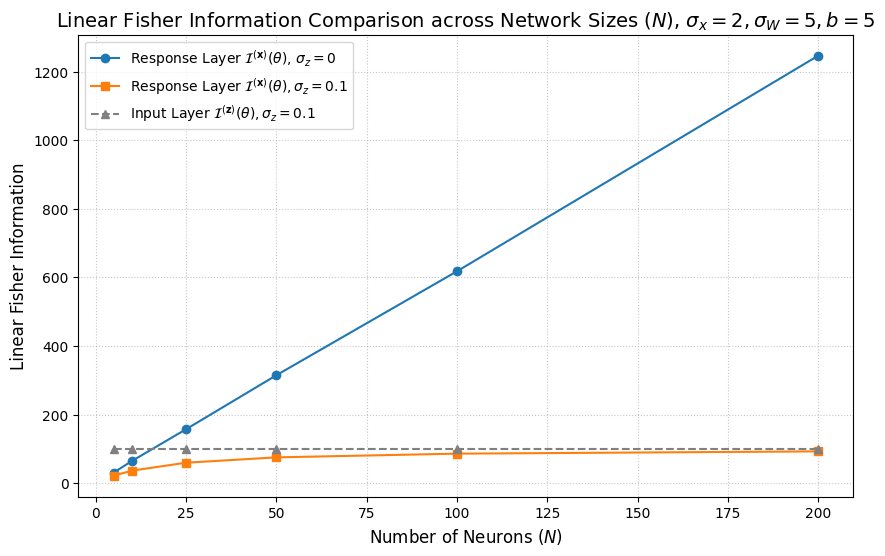

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

N_values = [5, 10, 25, 50, 100, 200]
sigma_W = 5
sigma_x = 2
b = 5
n_networks = 200
theta_values = np.linspace(0, 2*np.pi, 100)

sigma_z_values = [0, 0.1]

results_x = {0: [], 0.1: []}
results_z = {0: [], 0.1: []}

for sigma_z in sigma_z_values:
    for N in N_values:
        network_results_x = []
        network_results_z = []

        for network in range(n_networks):
            W = np.random.normal(0, sigma_W, (N, 2))
            Q = (sigma_z**2) * (W @ W.T) + (sigma_x**2) * np.eye(N)

            theta_results_x = []
            theta_results_z = []

            for theta in theta_values:
                mu_prime = np.array([-np.sin(theta), np.cos(theta)])

                # Input Fisher Information for z
                if sigma_z > 0:
                    FI_z = (mu_prime @ mu_prime) / (sigma_z**2)
                else: # Discard Fisher
                  FI_z = np.nan

                # Response Fisher Information for x
                v = W @ mu_prime
                FI_x = v @ np.linalg.solve(Q, v)

                theta_results_x.append(FI_x)
                theta_results_z.append(FI_z)

            network_results_x.append(np.mean(theta_results_x))
            network_results_z.append(np.mean(theta_results_z))

        results_x[sigma_z].append(np.mean(network_results_x))
        results_z[sigma_z].append(np.mean(network_results_z))


plt.figure(figsize=(10, 6))

# Response layer cases
plt.plot(N_values, results_x[0], 'o-', color='tab:blue',
         label=r'Response Layer $\mathcal{I}^{(\mathbf{x})}(\theta)$, $\sigma_z = 0$')

plt.plot(N_values, results_x[0.1], 's-', color='tab:orange',
         label=r'Response Layer $\mathcal{I}^{(\mathbf{x})}(\theta), \sigma_z = 0.1 $')

# Input layer case
plt.plot(N_values, results_z[0.1], '^--', color='gray',
         label=r'Input Layer $\mathcal{I}^{(\mathbf{z})}(\theta), \sigma_z = 0.1$ ')

plt.xlabel('Number of Neurons ($N$)', fontsize=12)
plt.ylabel('Linear Fisher Information', fontsize=12)
plt.title(r'Linear Fisher Information Comparison across Network Sizes ($N$), $ \sigma_x = 2, \sigma_W = 5, b = 5 $', fontsize=14)
plt.legend(fontsize=10, loc='upper left')
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

For the noiseless input, the Linear Fisher Information of the (response layer) $\mathcal{I}^{(\mathbf{x})}(\theta) $grows linearly to $ \infty \text{ as } N → \infty $. This implies there is unlimited information passsed onto the input layer from the unbounded neural network. For the case for noisy input, $\mathcal{I}^{(\mathbf{x})}(\theta)$ asymptotically converges to  $\mathcal{I}^{(\mathbf{z})}(\theta)$ as N grows to $\infty$ .

Under input with zero noise ($\sigma_z = 0$), the signal is lossless.
The addition of more neurons provides more independent measurings of the propagated signal. As $N$ grows to infinity, estimation variance shrinks to zero and equivalently the Fisher information grows unboundedly.

However, under noisy input ($\sigma_z > 0$), linear fisher information is bounded by $\mathcal{I}^{(\mathbf{z})}(\theta)$. Increasing N has a montonic non decreasing relationship with $\mathcal{I}^{(\mathbf{x})}(\theta)$.The data processing inequality guarantees this so once $N$ is sufficiently large, the curve plateaus and is capped at the input layer's limit.

 $\mathcal{I}^{(\mathbf{x})}(\theta)$ is independent of bias $b$ because this constant tranformation, is independent of $\theta$ and thus contributes nothing to $\mathbf{f}'(\theta)$.
 However $\mathcal{I}^{(\mathbf{x})}(\theta)$ grows with $\sigma_W$ since larger synaptic weights amplify signal sensitivity.

Information only matches $\mathbf{z}$ when network size is huge ($\sigma_z > 0$, $N \to \infty$) whereby the all noise is absorbed by the saturation of network.Matching happens when there is zero internal noise ($\sigma_x \to 0$) to produce a lossless channel.


# 3.4

The shift from a linear Gaussian chain and a full model with thresholding and Poisson variability renders key differences of information behaviour.

In a Poisson model, variance equals the mean, so trial-to-trial noise grows linearly with the signal, which prevents the model from exhibiting unboundedly growing information with network size like in the Gaussian case.  
The thresholding renders certain subpar neurons to be removed from the chain's processing and contributes no information. All silent neurons result in sharp non smooth drops in information contribution.

To see how the simplified model aligns with Q2 decoder performances, you look to the Cramér-Rao bound, which dictates that the empirical Standard Error ($\text{SE}$) of any unbiased decoder is lower-bounded by $1/\sqrt{\mathcal{I}(\theta)}$. By calculating the standard error of your decoders across trials in Q2 and comparing them directly against these analytical Fisher constraints, you can test how close the decoders come to theoretical optimal performance; any discrepancies where empirical SE exceeds the bound usually happen because threshold-induced non-linearities create complex distributions that sub-optimal decoders fail to fully exploit.

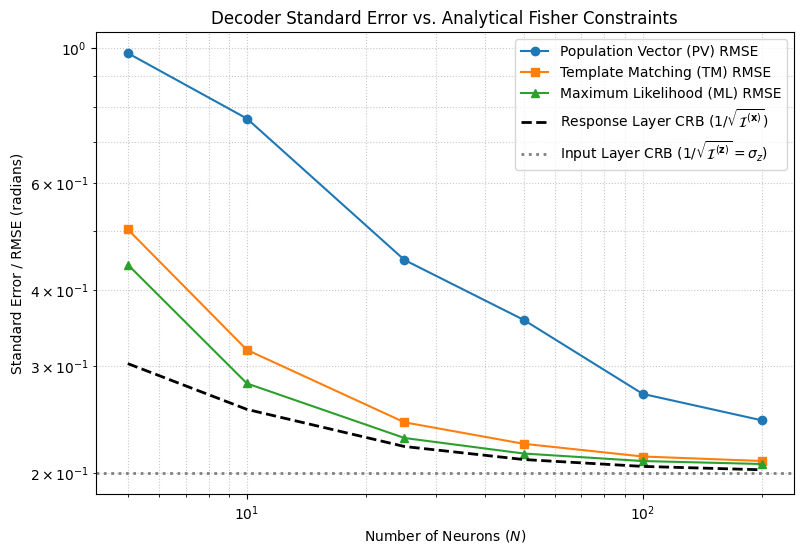

bound <= sigma_z for all N: False
N=5    bound=0.3028  ML RMSE=0.4405  ratio=1.45
N=10   bound=0.2546  ML RMSE=0.2809  ratio=1.10
N=25   bound=0.2212  ML RMSE=0.2285  ratio=1.03
N=50   bound=0.2106  ML RMSE=0.2154  ratio=1.02
N=100  bound=0.2052  ML RMSE=0.2094  ratio=1.02
N=200  bound=0.2025  ML RMSE=0.2070  ratio=1.02


In [21]:
# 3.4: empirical decoder RMSE vs analytical Fisher bounds
N_list  = [5, 10, 25, 50, 100, 200]
sigma_W = 5.0
sigma_z = 0.2
b       = 5.0
n_networks = 40

# Poisson mean approx b for zero-mean W
sigma_x_eff = np.sqrt(b)

se_decoders  = {"PV": [], "TM": [], "ML": []}
crb_response = []
crb_input    = []

for N in N_list:
    # mse_an array of per-network MSEs
    mse_dict = evaluate_decoders(
        N=N, sigma_W=sigma_W, sigma_z=sigma_z, b=b,
        n_networks=n_networks, n_stim=18, n_trials=10, seed=0
    ) # noiseless=False
    for dec in ["PV", "TM", "ML"]:
        # Average over networks then square root
        se_decoders[dec].append(np.sqrt(np.mean(mse_dict[dec])))

    # 2. Analytical linear Fisher information -> Cramér-Rao bound (1/sqrt(FI))
    fi_x_nets = []
    for k in range(n_networks):
        rng = np.random.default_rng(0 * 100_000 + k)
        W = rng.normal(0, sigma_W, size=(N, 2))
        Q = (sigma_z**2) * (W @ W.T) + (sigma_x_eff**2) * np.eye(N)

        # For |mu'| = 1, mean over theta of mu'^T M mu' = trace(M)/2, with M = W^T Q^-1 W.
        M = W.T @ np.linalg.solve(Q, W)
        fi_x_nets.append(np.trace(M) / 2)

    crb_response.append(1.0 / np.sqrt(np.mean(fi_x_nets)))
    crb_input.append(sigma_z)                           # FI_z = 1/sigma_z^2, i.e bound = sigma_z

# Plot comparison (unchanged apart from log axes)
plt.figure(figsize=(9, 6))
plt.plot(N_list, se_decoders["PV"], 'o-', label='Population Vector (PV) RMSE')
plt.plot(N_list, se_decoders["TM"], 's-', label='Template Matching (TM) RMSE')
plt.plot(N_list, se_decoders["ML"], '^-', label='Maximum Likelihood (ML) RMSE')
plt.plot(N_list, crb_response, 'k--', linewidth=2,
         label=r'Response Layer CRB ($1/\sqrt{\mathcal{I}^{(\mathbf{x})}}$)')
plt.axhline(sigma_z, color='gray', linestyle=':', linewidth=2,
            label=r'Input Layer CRB ($1/\sqrt{\mathcal{I}^{(\mathbf{z})}} = \sigma_z$)')
plt.xscale("log"); plt.yscale("log")                    # CHANGED: log axes make the plateau and gap visible
plt.xlabel('Number of Neurons ($N$)')
plt.ylabel('Standard Error / RMSE (radians)')
plt.title('Decoder Standard Error vs. Analytical Fisher Constraints')
plt.legend()
plt.grid(True, which="both", linestyle=':', alpha=0.7)
plt.show()

# Sanity checks
print("bound <= sigma_z for all N:", all(c <= sigma_z + 1e-9 for c in crb_response))
for N, c, ml in zip(N_list, crb_response, se_decoders["ML"]):
    print(f"N={N:<4} bound={c:.4f}  ML RMSE={ml:.4f}  ratio={ml/c:.2f}")

 We can see the empirical Standard Errors (SE) of the decoders are strictly bounded from below by the analytical Cramér-Rao constraints ($1/\sqrt{\mathcal{I}^{(\mathbf{x})}}$ and $\sigma_z = 0.2$). Template Matching (TM) and Population Vector (PV) mirror with the theoretical ideals, steadily decreasing with $N$ until TM saturates at the response layer bound near $0.2$ radians. PV maintains a consistent offset above this limit due to biases from non-uniform tuning.
 The Poisson ML formula idealistically assumes purely independent Poisson variability and is violated by the truth ($\sigma_z = 0.2$) and ReLU truncation happening in the full simulation, which casues the offset from PV



# Question 4
# 4.1(a)
This updated version builds on the simplified linear-Gaussian model by handling both threshold non-linearities and signal-dependent variability. ReLU rectification is fed directly into the expected tuning curves $\mathbf{f}(\theta) = \langle \max(W_{\text{in}}\mathbf{z} + \mathbf{b}, 0) \rangle$ and introduces $G(\theta)$, to scales how much input noise $\mathbf{n}$ propagates through neurons based on their probability of being active above threshold. Setting $\Sigma_x = \text{diag}(\mathbf{f}(\theta))$ rather than a constant variance corresponds to equality of (sampled) mean and variance for each neuron, directly exhibiting signal-dependent poisson variability.

The model still doesn't quite satisfy all key non-Gaussian and non-linear features of the full ReLU-Poisson system.
Since $p(\mathbf{x}\vert{}\mathbf{z})$ stays as a continuous Gaussian distribution, it fails to exhibit discrete integer spike counts, and the exact point-mass at zero caused when neurons are rectified below threshold.
While $\max(\cdot, 0)$ is used the trial-by-trial response $p(\mathbf{x}\vert{}\mathbf{z})$ is still modeled as an unclipped Gaussian; as a result, it allows unphysical negative firing rates and doesn't have the discrete spike inflation in probability at $x_i = 0$ form ReLU truncated trials.

#4.1(b)

Given a fixed stimulus $\theta$, the input layer is $\mathbf{z} = \boldsymbol{\mu}(\theta) + \mathbf{n}$, where the input noise is normally distributed as $\mathbf{n} \sim \mathcal{N}(\mathbf{0}, \sigma_z^2 \mathbf{I})$. From the conditional distribution $$p(\mathbf{x} \mid \mathbf{z}) = \mathcal{N}(\mathbf{f}(\theta) + G(\theta)W_{\text{in}}\mathbf{n}, \Sigma_x(\theta))$$
We can express response $\mathbf{x}$ as a linear combination of two independent zero-mean Gaussian random vectors:
\begin{equation}
\mathbf{x} = \mathbf{f}(\theta) + G(\theta)W_{\text{in}}\mathbf{n} + \boldsymbol{\epsilon}_x,
\end{equation}
where $\boldsymbol{\epsilon}_x \sim \mathcal{N}(\mathbf{0}, \Sigma_x(\theta))$ and $\mathbf{n} \perp \boldsymbol{\epsilon}_x$. Again, basic statistical theory tells us that any affine transformation and sum of independent multivariate Gaussians remains Gaussian, $\mathbf{x} \mid \theta$ follows a multivariate Gaussian distribution $p(\mathbf{x} \mid \theta) = \mathcal{N}(\mathbf{m}(\theta), Q(\theta))$.
By taking the expectation over $\mathbf{n}$ and $\boldsymbol{\epsilon}_x$
\begin{equation}
\mathbf{m}(\theta) = \mathbb{E}[\mathbf{x} \mid \theta] = \mathbf{f}(\theta) + G(\theta)W_{\text{in}}\mathbb{E}[\mathbf{n}] + \mathbb{E}[\boldsymbol{\epsilon}_x] = \mathbf{f}(\theta),
\end{equation}
where $\mathbf{f}(\theta) = \langle \max(W_{\text{in}}\mathbf{z} + \mathbf{b}, \mathbf{0}) \rangle$.
By exploiting the independence of $\mathbf{n}$ and $\boldsymbol{\epsilon}_x$, the symmetry of the diagonal gain matrix ($G(\theta)^T = G(\theta)$), and $\Sigma_x(\theta) = \text{diag}(\mathbf{f}(\theta))$, the marginal response covariance is:
\begin{equation}
Q(\theta) = \text{Cov}(\mathbf{x} \mid \theta) = G(\theta)W_{\text{in}}\,\text{Cov}(\mathbf{n})\,W_{\text{in}}^T G(\theta)^T + \Sigma_x(\theta) = \sigma_z^2 G(\theta) W_{\text{in}} W_{\text{in}}^T G(\theta) + \text{diag}(\mathbf{f}(\theta)).
\end{equation}


The linear Fisher information about $\theta$ in $\mathbf{x}$ is determined by the tuning curve sensitivity $\mathbf{m}'(\theta) = \mathbf{f}'(\theta)$ and the inverse response covariance $Q(\theta)^{-1}$ via $\mathcal{I}_{\text{lin}}^{(\mathbf{x})}(\theta) = \mathbf{f}'(\theta)^T Q(\theta)^{-1} \mathbf{f}'(\theta)$. Substituting the tuning curve derivative $\mathbf{f}'(\theta) = G(\theta)W_{\text{in}}\boldsymbol{\mu}'(\theta)$ and the covariance matrix $Q(\theta)$ gives:
\begin{equation}
\mathcal{I}_{\text{lin}}^{(\mathbf{x})}(\theta) = \boldsymbol{\mu}'(\theta)^T W_{\text{in}}^T G(\theta) \Big( \sigma_z^2 G(\theta) W_{\text{in}} W_{\text{in}}^T G(\theta) + \text{diag}(\mathbf{f}(\theta)) \Big)^{-1} G(\theta) W_{\text{in}} \boldsymbol{\mu}'(\theta).
\end{equation}

In [28]:
from scipy.stats import norm

def fisher_relu(W, b, sigma_z, thetas):
    """
    Linear Fisher information I_lin^(x), averaged over theta, Q4.1(b):
        f' = G W mu', Q = sigma_z^2 (G W)(G W)^T + diag(f), I = f'^T Q^-1 f'
    sigma_z = 0: G is the indicator and neurons with f = 0 are dropped
    sigma_z > 0: G = Phi(m/s), f = m Phi(m/s) + s phi(m/s).
    """
    s = sigma_z * np.linalg.norm(W, axis=1)
    out = []
    for th in thetas:
        mu  = np.array([np.cos(th), np.sin(th)])
        dmu = np.array([-np.sin(th), np.cos(th)])
        m = W @ mu + b

        if sigma_z == 0:
            G = (m > 0).astype(float)
            f = np.maximum(m, 0)
            keep = f > 0  # drop 0/0 neurons
        else:
            r = m / s
            G = norm.cdf(r)
            f = m * G + s * norm.pdf(r) # E[ReLU]
            keep = f > 1e-12

        if not keep.any():
            out.append(0.0)
            continue

        A  = G[keep, None] * W[keep]
        fp = A @ dmu
        Q  = sigma_z**2 * (A @ A.T) + np.diag(f[keep])   # response covariance
        out.append(fp @ np.linalg.solve(Q, fp))          # f'^T Q^-1 f'
    return np.mean(out)

def fisher_q3(W, b = 5, sigma_z, sigma_x2):
    """Q3 linear-Gaussian model, theta-averaged: trace(W^T Q^-1 W)/2 """
    Q = sigma_z**2 * (W @ W.T) + sigma_x2 * np.eye(W.shape[0])
    return np.trace(W.T @ np.linalg.solve(Q, W)) / 2

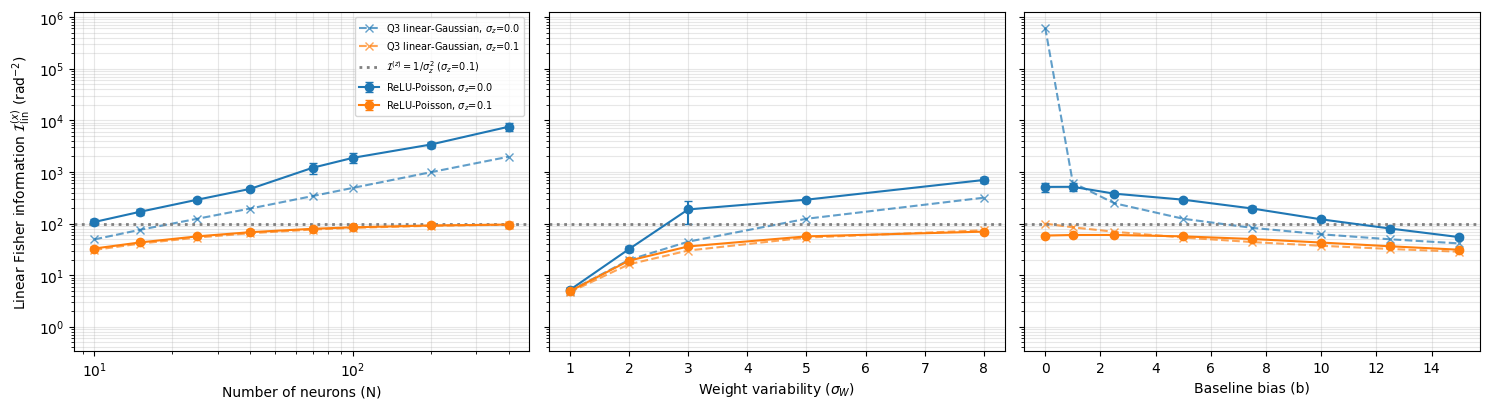

In [31]:
thetas = np.linspace(0, 2*np.pi, 36, endpoint=False)
n_networks = 40
base = dict(N=25, sigma_W=5.0, b=5.0)

def fisher_sweep(parameter, values, sigma_z, model="relu"):
    means, sems = [], []
    for v in values:
        p = {**base, parameter: v}
        vals = []
        for k in range(n_networks):
            rng = np.random.default_rng(k)  # same networks for every setting
            W = rng.normal(0, p["sigma_W"], size=(p["N"], 2))
            if model == "relu":
              vals.append(fisher_relu(W, p["b"], sigma_z, thetas))
            else:
              vals.append(fisher_q3(W, p["b"], sigma_z, sigma_x2=max(p["b"], 1e-3))) # constant sigma_x^2, independent of b

        vals = np.array(vals)
        means.append(vals.mean()); sems.append(vals.std(ddof=1)/np.sqrt(n_networks))
    return np.array(means), np.array(sems)

N_values     = [10, 15, 25, 40, 70, 100, 200, 400]
sigma_values = [1, 2, 3, 5, 8]
b_values     = [0, 1, 2.5, 5, 7.5, 10, 12.5, 15]
sweeps = [("N", N_values, "Number of neurons (N)"),
          ("sigma_W", sigma_values, r"Weight variability ($\sigma_W$)"),
          ("b", b_values, "Baseline bias (b)")]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (par, vals, lab) in zip(axes, sweeps):
    for sz, c in [(0.0, "C0"), (0.1, "C1")]:
        m, s = fisher_sweep(par, vals, sz, "relu")
        ax.errorbar(vals, m, yerr=s, color=c, marker="o", capsize=3,
                    label=fr"ReLU-Poisson, $\sigma_z$={sz}")
        mq, _ = fisher_sweep(par, vals, sz, "q3")
        ax.plot(vals, mq, color=c, ls="--", marker="x", alpha=0.7,
                label=fr"Q3 linear-Gaussian, $\sigma_z$={sz}")
    ax.axhline(1/0.1**2, color="gray", ls=":", lw=2, label=r"$\mathcal{I}^{(z)}=1/\sigma_z^2$ ($\sigma_z$=0.1)")
    ax.set_xlabel(lab); ax.set_yscale("log"); ax.grid(True, which="both", alpha=0.3)
axes[0].set_xscale("log")
axes[0].set_ylabel(r"Linear Fisher information $\mathcal{I}^{(x)}_{\rm lin}$ (rad$^{-2}$)")
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

In [32]:
for N in [10, 25, 50, 100]:
    I_nets = np.array([fisher_relu(np.random.default_rng(k).normal(0, 5.0, size=(N, 2)), 5.0, 0.0, thetas)
                       for k in range(n_networks)])
    ml = evaluate_decoders(N=N, sigma_z=0.0, n_networks=n_networks, n_stim=18, n_trials=10, seed=0)["ML"]
    print(f"N={N:<4} mean 1/I = {np.mean(1/I_nets):.4f} | ML MSE = {ml.mean():.4f} | ratio {ml.mean()/np.mean(1/I_nets):.2f}")

N=10   mean 1/I = 0.0124 | ML MSE = 0.0293 | ratio 2.36
N=25   mean 1/I = 0.0041 | ML MSE = 0.0076 | ratio 1.85
N=50   mean 1/I = 0.0020 | ML MSE = 0.0032 | ratio 1.64
N=100  mean 1/I = 0.0009 | ML MSE = 0.0014 | ratio 1.67




For $\sigma_z=0$ the linear Fisher information of the ReLu Poisson approximation (ReLU Poiss) grows roughly linearly with $N$ and has no ceiling, rising from about $10^2$ at $N=10$ to about $8\times10^3$ at $N=400$. For $\sigma_z=0.1$ ReLU Poiss follows the same curve at small $N$ and then saturates just below the input-layer information $\mathcal{I}^{(\mathbf{z})}=1/\sigma_z^2=100$, so $\mathbf{x}$ never carries more information than $\mathbf{z}$. For $\sigma_z=0$, no such Cramer bound on information exits.  

Equivalent to the behaviour of the MSE in 2.3: information rises steeply with $\sigma_W$ at small $\sigma_W$ and more slowly beyond $\sigma_W\approx3$, reaching about $7\times10^2$ at $\sigma_W=8$ for $\sigma_z=0$. Linear Fisher Information decreases monotonically with $b$. For $\sigma_z=0.1$ the curves tend close to the ceiling $1/\sigma_z^2$ and depend only weakly on $\sigma_W$ and $b$ once $N$ and $\sigma_W$ are moderate.

The information results corroborate the decoder results at the level of scaling. When $\sigma_z = 0$, the linear growth of information $\mathcal{I}$ with $N$ mirrors the $1/N$ decrease in decoder error from Question 2.3. This occurs because each independent Poisson neuron adds a positive contribution of $G_i^2(\mathbf{w}_i\cdot\boldsymbol\mu'^2)/f_i$.

Conversely, when $\sigma_z > 0$, the saturation of $\mathcal{I}$ at $1/\sigma_z^2$ corresponds corresponds to amsymptotic behaviour near $\sigma_z^2$ in Question 2.4. Both saturation effects are driven by information-limiting covariances resulting from shared input noise.

$\sigma_W$ dependence corroborates with decoder also.For large $\sigma_W$, information grows more slowly than $ 1/ \sigma_w^2$ in Question 2.3. The $b$ dependence agrees to a partial degree. Information falls steadily with $b$, matching the rise in TM and ML error at large $b$ and the rise of PV error, but the decoders show a shallow error minimum near $b\approx2.5$ that the information does not.
No Fisher information measure can capture the PV's deterioration.

The linear-Gaussian model reproduces the linear growth with $N$,  with  saturation at $1/\sigma_z^2$. At $\sigma_z=0.1$ the two models almost fully collide, because near the ceiling the information is set by the shared-noise term, which they have in common. At $\sigma_z=0$ the ReLU-Pois information (relative to linear gaussian model) is two to four times larger and parallel in $N$. The differences are most fraught in $\sigma_W$ and $b$ dependencies. The linear-Gaussian information scales as $\sigma_W^2$ throughout and is independent of $b$ by construction, because $b$ only shifts the mean and $\sigma_x^2$ is a constant.

The full approximation provides why the decoder error depends on $b$ and $\sigma_w$ in the way described. Per neuron, the information  is $G_i^2(\mathbf{w}_i\cdot\boldsymbol\mu')^2/f_i$. Consequently, an increase of $b$ increases poisson variance without altering the gradient of the information curve and thus the information decreases.

This drives the observed increase in TM and ML error at large $b$, and it is absent from Question 3.  $f_i'^2/f_i$ grows roughly linearly rather than quadratically in $\sigma_W$. This accounts for the diminishing returns in Question 2.3, failed to be captured by question 3.The gain $G_i$ also shows that only the active neurons contribute, this explains why at  $b=0$ is different to moderate b values,  

The information is highest at $b\approx0$ whereas the decoders do best near $b\approx2.5$. At low $b$, neurons close to threshold have small $f_i$ and a discontinuous curve.